In [138]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')  # Gereksiz uyarıları gizle (Suppress warnings)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats  # İstatistiksel testler için (For statistical tests)

# Görselleştirme ve tablo ayarları (Visualization & display settings)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['axes.titleweight'] = 'bold'
pd.set_option('display.max_columns', 120)
pd.set_option('display.max_rows', 120)
pd.set_option('display.float_format', lambda x: '%.2f' % x)  # Ondalık gösterim (Float format)

# Olası veri seti yolları (Candidate dataset paths)
KAGGLE_PATH = Path('/kaggle/input/datasets/ghitaes/gender-violence-spain-dataset-20202024/Gender Violence Spain Dataset (2020-2024).csv')
LOCAL_PATH = Path('Gender Violence Spain Dataset (2020-2024).csv')
REPO_PATH = Path('Competitions/Gender Violence Spain Dataset 2020-2024/Gender Violence Spain Dataset (2020-2024).csv')

# Mevcut olan ilk dosya yolunu bul (Find the first existing path)
for candidate in [KAGGLE_PATH, LOCAL_PATH, REPO_PATH]:
    if candidate.exists():
        DATA_PATH = candidate
        break
else:
    raise FileNotFoundError('CSV dosyası bulunamadı. Kaggle yolunu kontrol edin veya CSV dosyasını notebook yanına koyun.')

# Veriyi yükle ve kopyasını oluştur (Load data and create a working copy)
print(f"Kullanılan dosya yolu: {DATA_PATH}")
data = pd.read_csv(DATA_PATH)
df = data.copy()
display(df.head())

Kullanılan dosya yolu: Gender Violence Spain Dataset (2020-2024).csv


,Region,Year,Violence_Victims,Complaints,Funding_EUR,School_Leaving(%),Unemployment_Rate(%)
0,Andalucía,2020,6813,30847,"€ 15,286,964.44",21.80,22.30
1,Aragón,2020,725,3277,"€ 4,657,150.64",14.20,11.70
2,Asturias,2020,622,2650,"€ 2,873,028.43",8.90,14.10
3,Baleares,2020,1002,5880,"€ 4,142,542.43",21.30,16.10
4,Canarias,2020,1734,8926,"€ 5,921,683.67",18.20,22.60


In [139]:
df["Funding_EUR"] = pd.to_numeric(
    df["Funding_EUR"].astype(str).str.replace("€", "").str.replace(",", "").str.strip(),
    errors='coerce'
)
print(f"Eksik Funding_EUR Gözlem Sayısı: {df['Funding_EUR'].isna().sum()}")
display(df[df["Funding_EUR"].isna()])

Eksik Funding_EUR Gözlem Sayısı: 10


,Region,Year,Violence_Victims,Complaints,Funding_EUR,School_Leaving(%),Unemployment_Rate(%)
14,Navarra,2020,289,1796,NaN,10.80,10.10
15,País Vasco,2020,559,5355,NaN,6.50,9.50
33,Navarra,2021,299,1630,NaN,8.40,10.71
34,País Vasco,2021,614,5357,NaN,5.30,10.30
52,Navarra,2022,338,2352,NaN,5.20,5.20
53,País Vasco,2022,783,6095,NaN,6.10,6.10
71,Navarra,2023,398,3017,NaN,6.50,9.94
72,País Vasco,2023,754,6512,NaN,6.70,7.74
90,Navarra,2024,426,3816,NaN,9.90,7.64
91,País Vasco,2024,766,6675,NaN,5.00,8.10


**Sadece Navarra ve País Vasco bölgelerine ait veriler olmadığı için bu iki bölge veri setinden silinir.**

In [140]:
df["Vi_Co_ratio"]=df["Violence_Victims"]/df["Complaints"] #Violance/Complaints ratio
df["Co_Vi_ratio"]=df["Complaints"]/df["Violence_Victims"] #Complaints/Violance ratio
df_z=df.dropna(subset=["Funding_EUR"]).copy()
display(df_z["Funding_EUR"].isnull().values.sum())

np.int64(0)

$H_0$ (Yokluk Hipotezi / Null Hypothesis): Devletin ayırdığı fon miktarı (Funding_EUR) ile şikayet başına düşen şiddet mağduru oranı (Vi_Co_ratio) arasında istatistiksel olarak anlamlı bir ilişki (korelasyon) yoktur ($r = 0$ veya $\rho = 0$).

$H_1$ (Alternatif Hipotez / Alternative Hypothesis): Devletin ayırdığı fon miktarı (Funding_EUR) ile şikayet başına düşen şiddet mağduru oranı (Vi_Co_ratio) arasında istatistiksel olarak anlamlı bir ilişki vardır ($r \neq 0$ veya $\rho \neq 0$).

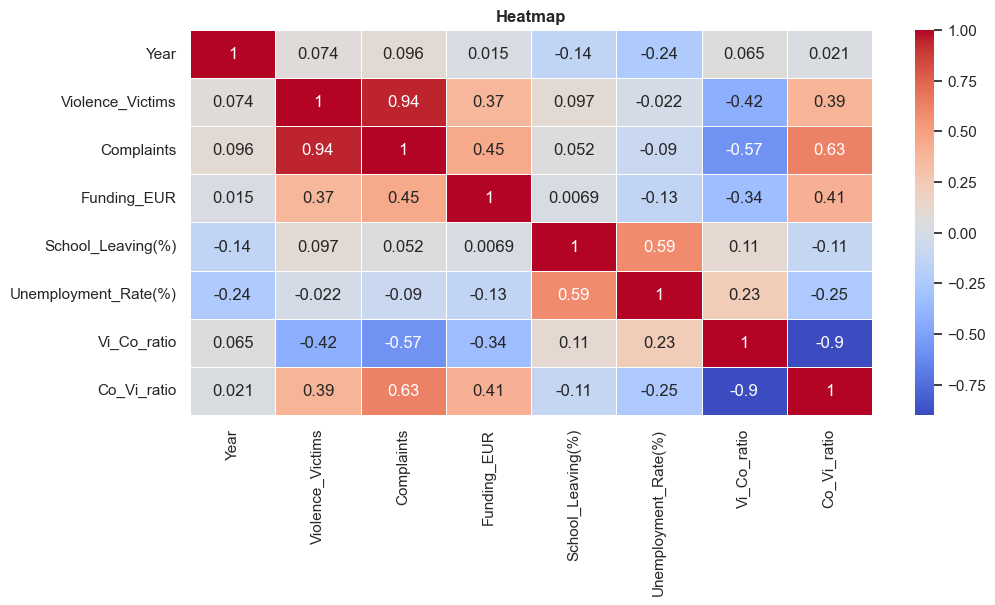

In [141]:
df_numeric=df_z.select_dtypes(include=["int64","float64"])
corr_matrix=df_numeric.corr()
sns.heatmap(data=corr_matrix,fmt=".2g",cmap="coolwarm",annot=True,linewidths=0.5)
plt.title("Heatmap")
plt.show()

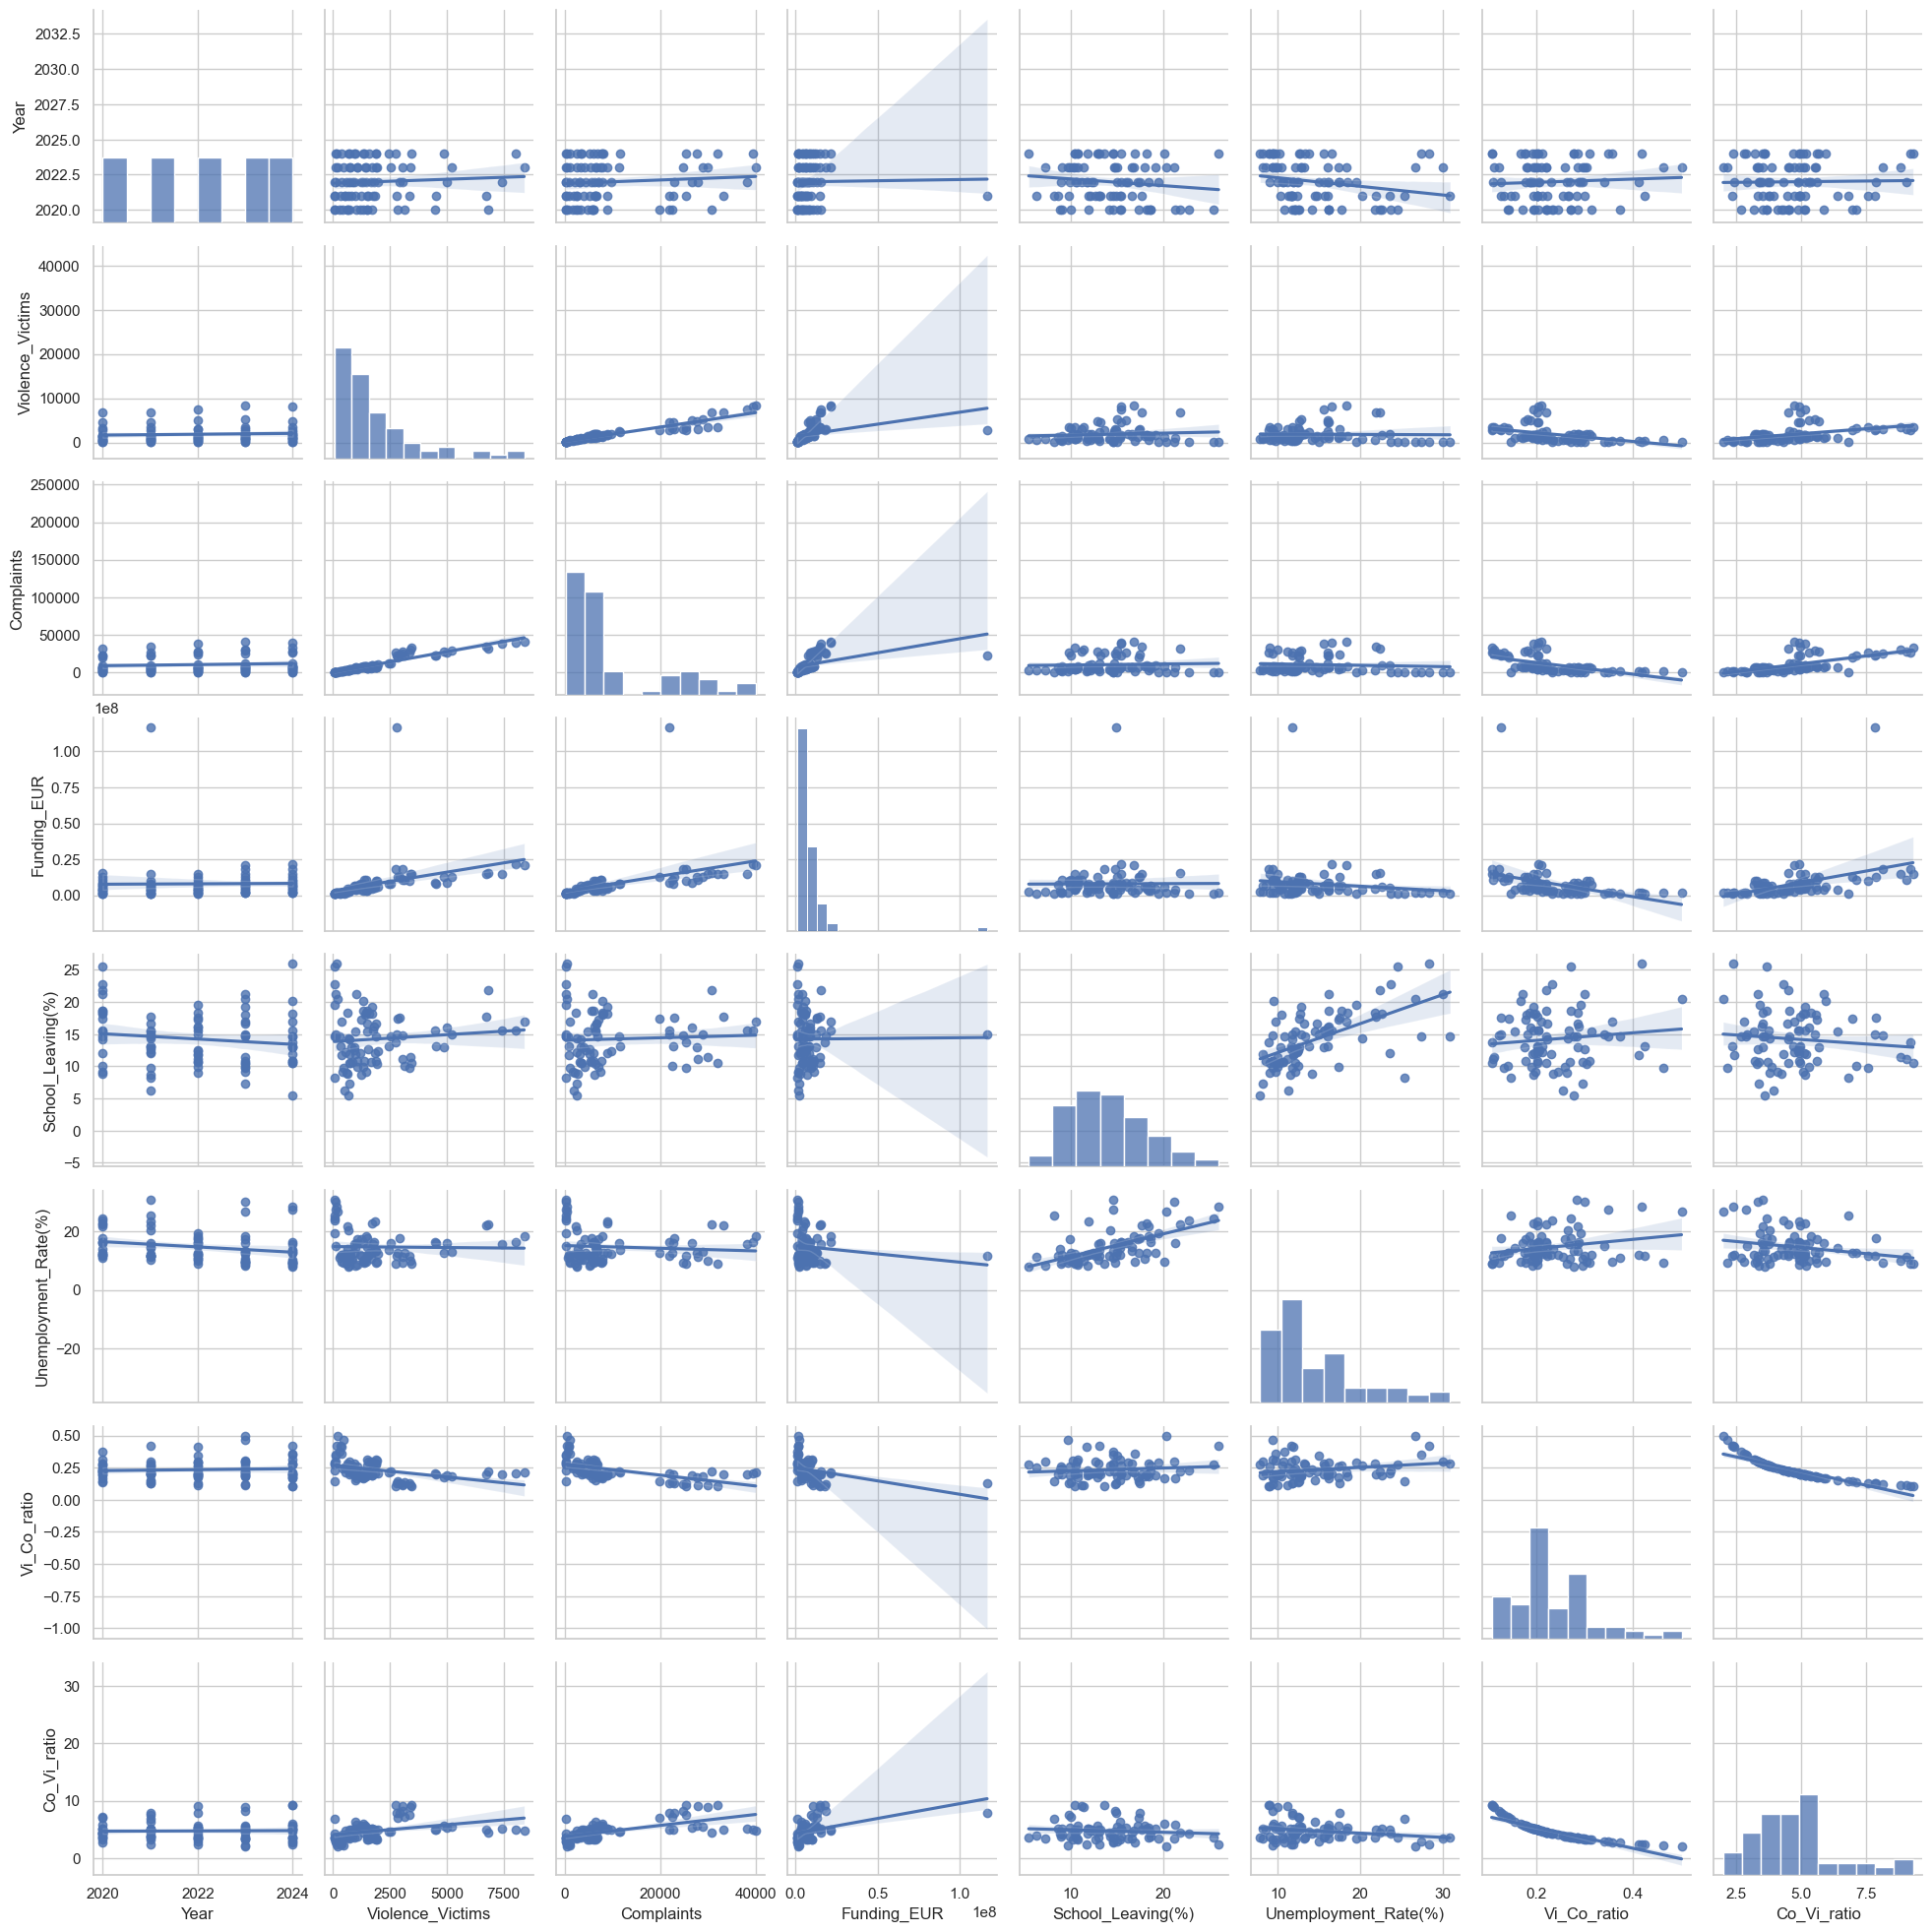

In [142]:
sns.pairplot(data=df_z,kind="reg");

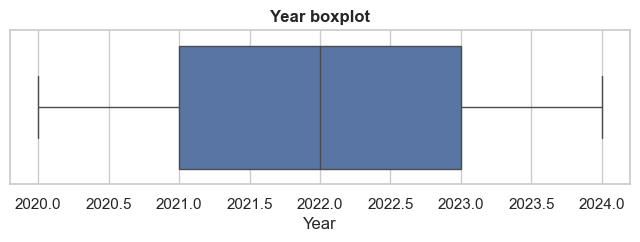

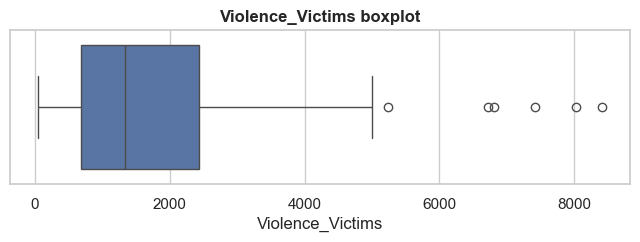

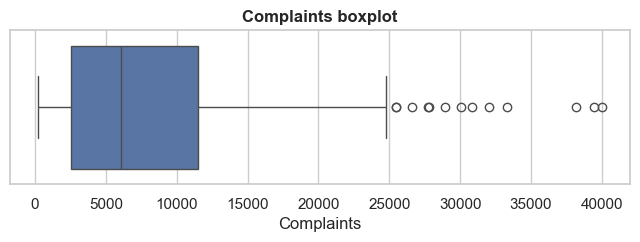

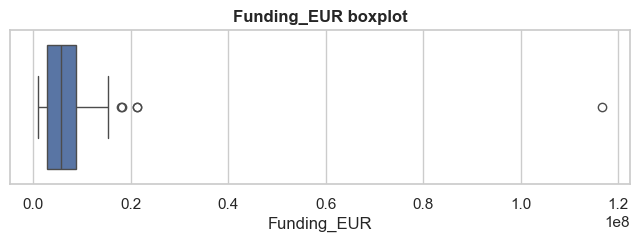

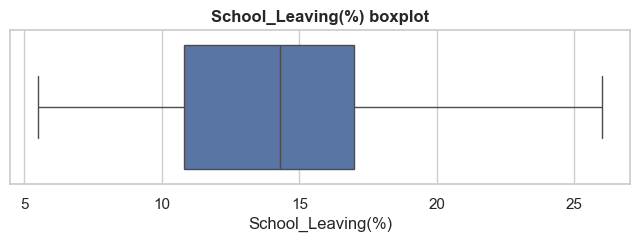

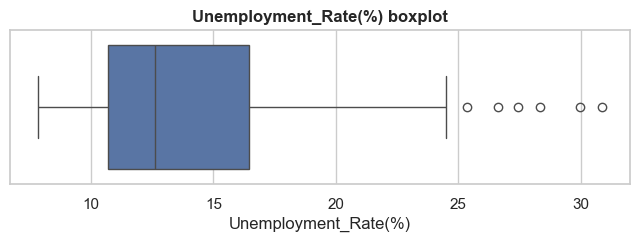

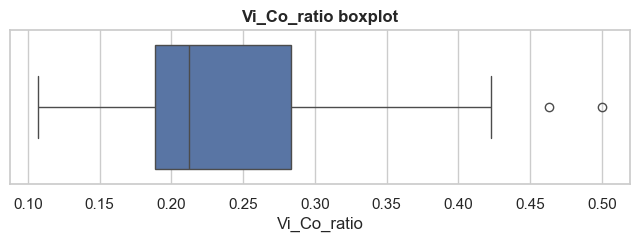

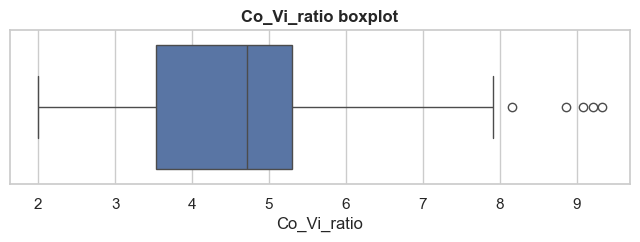

In [143]:
df_numeric=df_z.select_dtypes(include=["int64","float64"])
for i in df_numeric:
    plt.figure(figsize=(8,2))
    sns.boxplot(x=df_numeric[i]);
    plt.title(f"{i} boxplot")
    plt.show()

In [144]:
for i in df_numeric:
    Q1=df_z[i].quantile(0.25)
    Q3=df_z[i].quantile(0.75)
    IQR=Q3-Q1
    lower=Q1-1.5*IQR
    upper=Q3+1.5*IQR
    outliars=df_z[(df_z[i]<lower )|( df_z[i]>upper)]
    print(f"{i} için aykırı değerler")
    display(len(outliars))

Year için aykırı değerler


0

Violence_Victims için aykırı değerler


6

Complaints için aykırı değerler


13

... (6 outputs left out)

Vi_Co_ratio için aykırı değerler


2

Co_Vi_ratio için aykırı değerler


5

In [145]:
from scipy.stats import shapiro
values=df_z[["Vi_Co_ratio","Funding_EUR"]]
for col in values.columns:
    test_ist,p_value=shapiro(values[col])
    if p_value<0.05:
        print(f"{col} normal dağılmaz.\np-value:{p_value:.4f}")
    else:
        print(f"{col} normal dağılır.np-value:{p_value:.4f}")

Vi_Co_ratio normal dağılmaz.
p-value:0.0003
Funding_EUR normal dağılmaz.
p-value:0.0000


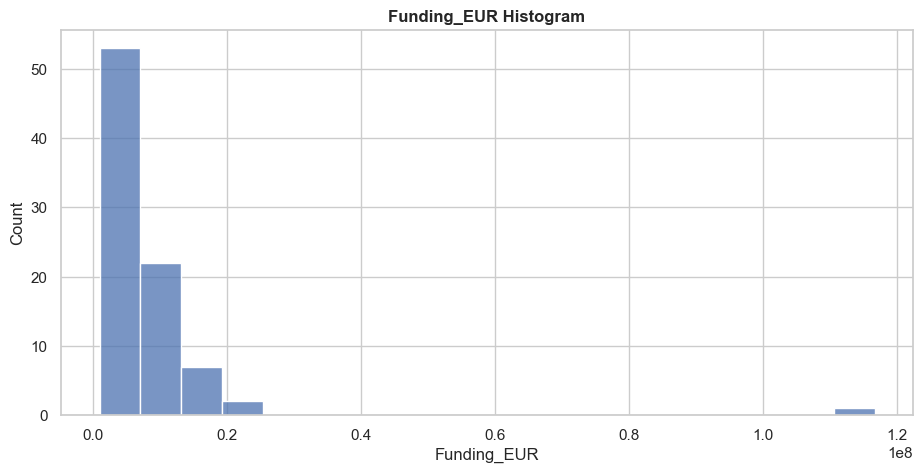

In [146]:
sns.histplot(data=df_z["Funding_EUR"])
plt.title("Funding_EUR Histogram")
plt.show()

In [147]:
df_z["Log_Funding_EUR"]=np.log(df_z["Funding_EUR"])
test_ist,p_value=shapiro(df_z["Log_Funding_EUR"])
if p_value<0.05:
    print(f"normal dağılmaz.\n" \
    f"test ist: {test_ist:.4f}\n"
    f"p value: {p_value:.4f}")
else:
    print("Log_Funding_EUR normal dağılır\n"
    f"test ist: {test_ist:.4f}\n" \
    f"p value: {p_value:.4f}")

normal dağılmaz.
test ist: 0.9579
p value: 0.0073


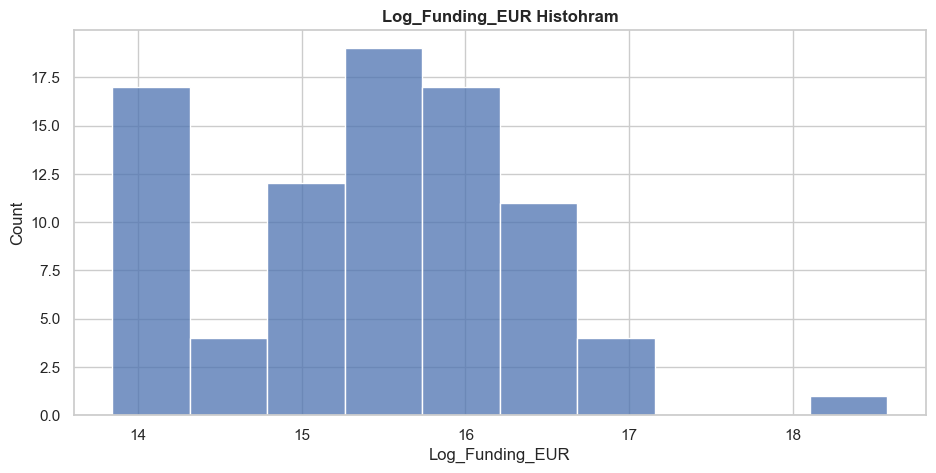

count   85.00
mean    15.44
std      0.90
min     13.85
25%     14.87
50%     15.57
75%     15.99
max     18.57
Name: Log_Funding_EUR, dtype: float64

In [148]:
sns.histplot(data=df_z["Log_Funding_EUR"])
plt.title("Log_Funding_EUR Histohram")
plt.show()
df_z["Log_Funding_EUR"].describe().T

,Region,Year,Violence_Victims,Complaints,Funding_EUR,School_Leaving(%),Unemployment_Rate(%),Vi_Co_ratio,Co_Vi_ratio,Log_Funding_EUR
27,Cataluña,2021,2782,21857,116666598.59,14.90,11.70,0.13,7.86,18.57
76,Andalucía,2024,8020,39430,21306856.12,15.50,16.46,0.20,4.92,16.87
57,Andalucía,2023,8407,39990,21269335.29,16.90,18.24,0.21,4.76,16.87
65,Cataluña,2023,3038,24789,18243425.19,14.80,9.34,0.12,8.16,16.72
84,Cataluña,2024,2768,25489,18061671.23,13.70,8.90,0.11,9.21,16.71


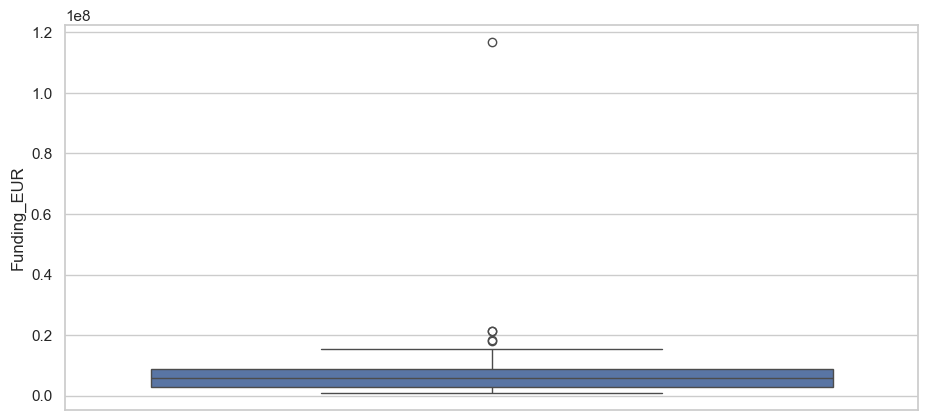

In [149]:
sns.boxplot(data=df_z["Funding_EUR"]);
df_z.sort_values(by="Funding_EUR",ascending=False).head()

**Cataluña verisinin 2021 Funding_EUR değeri veri girişi hatasıdır başında bir adet 1 hatalı girilmiştir.**

In [150]:
df_z.loc[(df_z["Region"] == "Cataluña") & (df_z["Year"] == 2021), "Funding_EUR"] = 11666598.59
df_z["Log_Funding_EUR"] = np.log(df_z["Funding_EUR"])
test_ist, p_value = shapiro(df_z["Log_Funding_EUR"])
if p_value < 0.05:
    print(f"Log_Funding_EUR normal dağılmaz.\nTest İstatistiği (W): {test_ist:.4f}\np-değeri: {p_value:.4f}")
else:
    print(f"Log_Funding_EUR normal dağılır.\nTest İstatistiği (W): {test_ist:.4f}\np-değeri: {p_value:.4f}")

Log_Funding_EUR normal dağılmaz.
Test İstatistiği (W): 0.9516
p-değeri: 0.0030


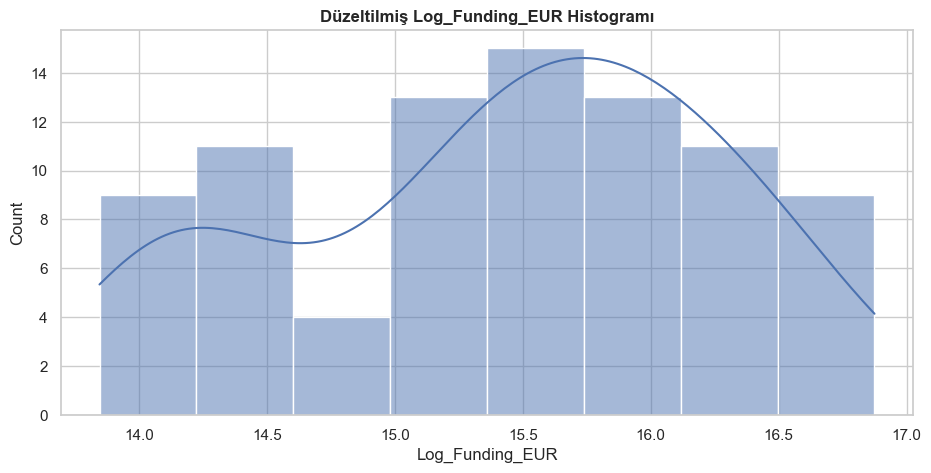

In [151]:
sns.histplot(data=df_z["Log_Funding_EUR"], kde=True)
plt.title("Düzeltilmiş Log_Funding_EUR Histogramı")
plt.show()

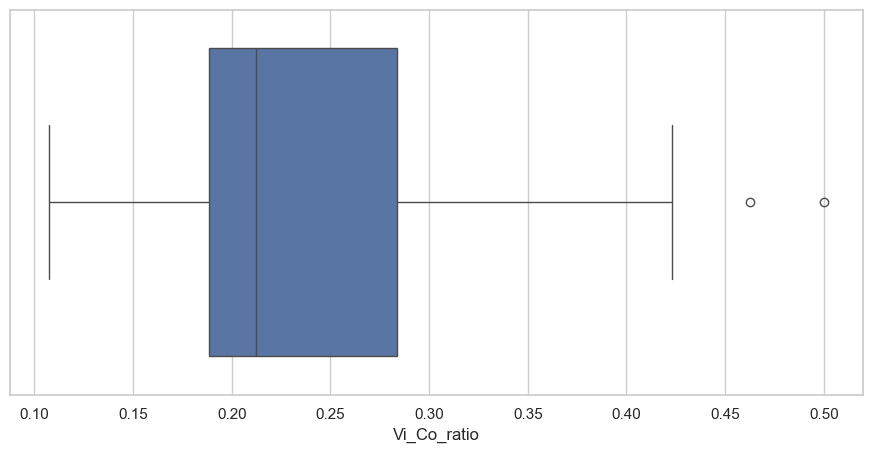

In [152]:
sns.boxplot(x=df_z["Vi_Co_ratio"]);

count   85.00
mean     0.23
std      0.08
min      0.11
25%      0.19
50%      0.21
75%      0.28
max      0.50
Name: Vi_Co_ratio, dtype: float64

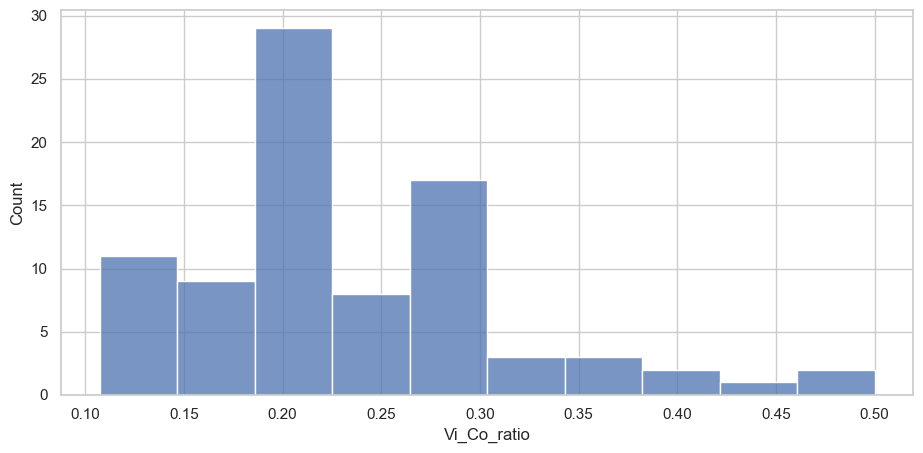

In [153]:
sns.histplot(data=df_z["Vi_Co_ratio"]);
df_z["Vi_Co_ratio"].describe().T

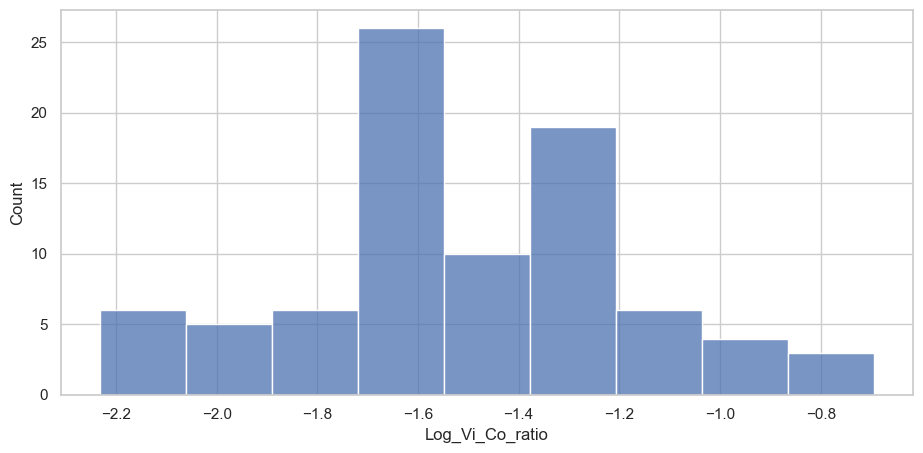

In [154]:
df_z["Log_Vi_Co_ratio"]=np.log(df_z["Vi_Co_ratio"])
sns.histplot(data=df_z["Log_Vi_Co_ratio"]);

In [155]:
test_ist,p_value=shapiro(df_z["Log_Vi_Co_ratio"])
if p_value<0.05:
    print("normal dağılmaz.")
else:
    print("Log_Vi_Co_ratio normal dağılır\n"
    f"test ist: {test_ist:.4f}\n" \
    f"p value: {p_value:.4f}")

Log_Vi_Co_ratio normal dağılır
test ist: 0.9797
p value: 0.2002


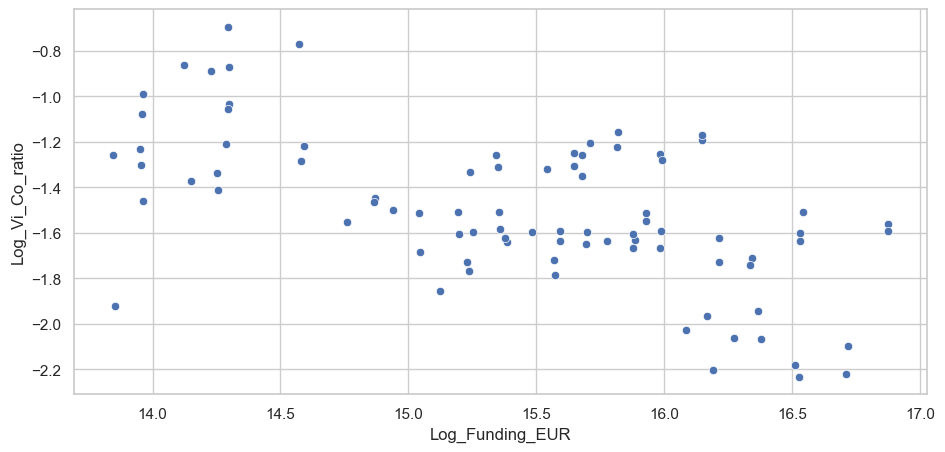

In [156]:
sns.scatterplot(data=df_z,x="Log_Funding_EUR",y="Log_Vi_Co_ratio");

In [157]:
from scipy.stats import spearmanr
rho_degeri, p_value = spearmanr(df_z["Funding_EUR"], df_z["Vi_Co_ratio"])
print(f"Spearman Korelasyon Katsayısı (rho): {rho_degeri:.4f}\n"
      f"p-değeri (p-value): {p_value:.4f}")
if p_value < 0.05:
    print(f"Karar: H0 reddedilir. Aralarında istatistiksel olarak anlamlı ve negatif bir ilişki vardır (rho = {rho_degeri:.2f}).")
else:
    print(f"Karar: H0 reddedilemez. Aralarında anlamlı bir ilişki yoktur (rho = {rho_degeri:.2f}).")

Spearman Korelasyon Katsayısı (rho): -0.5453
p-değeri (p-value): 0.0000
Karar: H0 reddedilir. Aralarında istatistiksel olarak anlamlı ve negatif bir ilişki vardır (rho = -0.55).


### **Sonuç** : 
Devletin ayırdığı fon miktarı (Funding_EUR) ile şikayet başına düşen şiddet mağduru oranı (Vi_Co_ratio) arasında istatistiksel olarak anlamlı, negatif yönlü ve orta güçte bir ilişki bulunmaktadır ($\rho = -0.55, p < 0.001$). Fon miktarının daha yüksek olduğu bölgelerde, yapılan şikayetlere kıyasla kesinleşmiş mağdur oranı daha düşük seyretmektedir.

### **Bölgeler Arasındaki Şiddet/Şikayet Oranları Arasında Fark Var Mı?** 

$H_0$ (Sıfır Hipotezi - Null Hypothesis): Tüm bölgelerin ortalama Vi_Co_ratio değerleri eşittir ($\mu_1 = \mu_2 = \dots = \mu_k$). Yani, bölgeler arasında ortalama Vi_Co_ratio açısından anlamlı bir fark yoktur.

$H_1$ (Alternatif Hipotez - Alternative Hypothesis): En az bir bölgenin ortalama Vi_Co_ratio değeri diğerlerinden farklıdır.

**Step 1: Normality test**

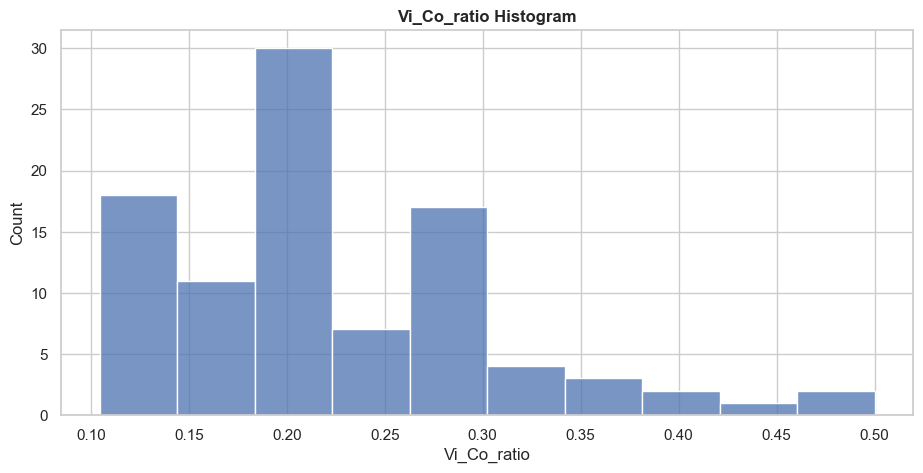

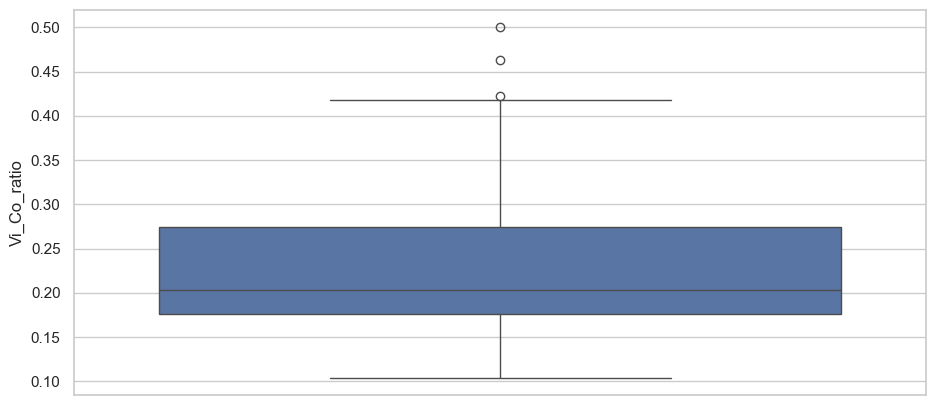

count   95.00
mean     0.22
std      0.08
min      0.10
25%      0.18
50%      0.20
75%      0.27
max      0.50
Name: Vi_Co_ratio, dtype: float64

In [158]:
sns.histplot(data=df["Vi_Co_ratio"])
plt.title("Vi_Co_ratio Histogram")
plt.show()
sns.boxplot(data=df["Vi_Co_ratio"])
plt.show()
display(df["Vi_Co_ratio"].describe())

In [159]:
from scipy.stats import shapiro
w_test,p_value=shapiro(df["Vi_Co_ratio"])
print(f"P value:{p_value:.4f}\n" \
f"Test ist.:{w_test:.4f}")
if p_value<0.05:
    print("H0 red edilir.\n" \
    "Veri normal dağılmaz.")
else:
    print("H0 red edilemez.\n" \
    "Veri normal dağılır.")

P value:0.0001
Test ist.:0.9340
H0 red edilir.
Veri normal dağılmaz.


In [160]:
Q1=df["Vi_Co_ratio"].quantile(0.25)
Q3=df["Vi_Co_ratio"].quantile(0.75)
IQR=Q3-Q1
lower=Q1-1.5*IQR
upper=Q3+1.5*IQR
display(df[df["Vi_Co_ratio"]>upper])
print(f"upper değeri:{upper:.4f}")

,Region,Year,Violence_Victims,Complaints,Funding_EUR,School_Leaving(%),Unemployment_Rate(%),Vi_Co_ratio,Co_Vi_ratio
35,La Rioja,2021,348,823,1360975.89,13.10,11.60,0.42,2.36
73,La Rioja,2023,455,983,2129337.72,9.70,9.38,0.46,2.16
75,Melilla,2023,201,402,1615042.38,20.40,26.63,0.50,2.00


upper değeri:0.4214


<Axes: xlabel='Log_Vi_Co_ratio', ylabel='Count'>

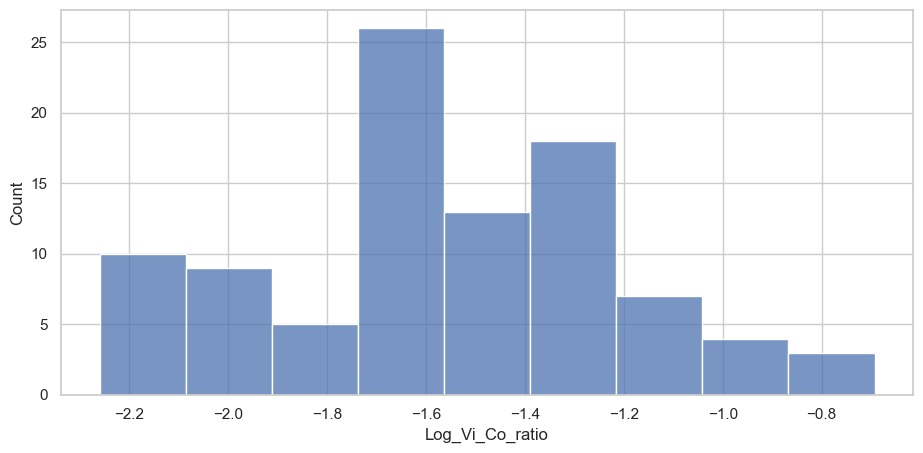

In [161]:
# Log transformation
df["Log_Vi_Co_ratio"]=np.log(df["Vi_Co_ratio"])
sns.histplot(data=df,x="Log_Vi_Co_ratio")

In [162]:
from scipy.stats import shapiro
w_test,p_value=shapiro(df["Log_Vi_Co_ratio"])
print(f"P value:{p_value:.4f}\n" \
f"Test ist.:{w_test:.4f}")
if p_value<0.05:
    print("H0 red edilir.\n" \
    "Veri normal dağılmaz.")
else:
    print("H0 red edilemez.\n" \
    "Veri normal dağılır.")

P value:0.0963
Test ist.:0.9772
H0 red edilemez.
Veri normal dağılır.


**Step 2: Equal Variance Test**

In [163]:
from scipy.stats import levene
groups = [df[df["Region"] == region]["Log_Vi_Co_ratio"] for region in df["Region"].unique()]
# Yıldız (*) operatörü (unpacking) ile listedeki her bir grubu levene fonksiyonuna ayrı birer argüman olarak gönderiyoruz.
w_test, p_value = levene(*groups)
print(f"W_test: {w_test:.4f}")
print(f"P value: {p_value:.4f}")
if p_value < 0.05:
    print("H0 reddedilir. Varyans homojenliği sağlanmaz.")
else:
    print("H0 reddedilemez. Varyans homojenliği sağlanır.")


W_test: 3.7533
P value: 0.0000
H0 reddedilir. Varyans homojenliği sağlanmaz.


In [164]:
import pingouin as pg
welch=pg.welch_anova(data=df,dv="Log_Vi_Co_ratio",between="Region")
welch

,Source,ddof1,ddof2,F,p_unc,np2
0,Region,18,28.05,88.54,0.00,0.88


**Sonuç: H0 red edilir. F=88.54 ve P value<0.001 tir. Bu yüzden bölgeler arasında anlamlı fark vardır.**
**Farkı anlamak için Games-Howel Post-Hoc testi yapılır.**

In [169]:
# Anlamlı fark bulunanlar.
games_howel=pg.pairwise_gameshowell(data=df,dv="Log_Vi_Co_ratio",between="Region")
display(games_howel[games_howel["pval"]<0.05].sort_values(by="hedges",key=abs,ascending=False).reset_index().head())
games_howel[games_howel["pval"]<0.05].shape

,index,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,104,Castilla y Leon,País Vasco,-1.19,-2.16,0.97,0.03,27.81,4.99,0.00,15.88
1,115,Castilla-La Mancha,País Vasco,-1.28,-2.16,0.88,0.04,24.72,5.28,0.00,14.12
2,149,Extremadura,País Vasco,-1.30,-2.16,0.86,0.04,22.67,6.35,0.00,12.95
3,160,La Rioja,País Vasco,-0.91,-2.16,1.25,0.06,21.96,7.20,0.00,12.54
4,98,Castilla y Leon,Galicia,-1.19,-1.66,0.47,0.02,21.09,6.65,0.00,12.05


(105, 10)

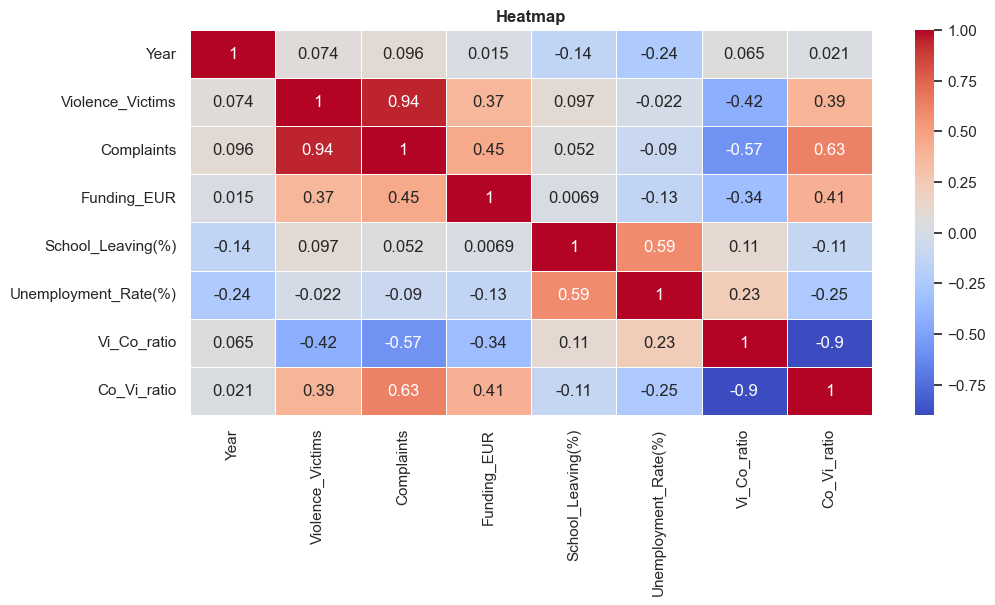

In [166]:
corr_matrix=df_numeric.corr()
sns.heatmap(data=corr_matrix,fmt=".2g",cmap="coolwarm",annot=True,linewidths=0.5)
plt.title("Heatmap")
plt.show()

In [167]:
from scipy import stats
stat_fund, p_fund = stats.shapiro(df_z["Funding_EUR"])
stat_ratio, p_ratio = stats.shapiro(df_z["Vi_Co_ratio"])

print(f"Shapiro-Wilk Normallik Testi:")
print(f"Funding_EUR p-değeri: {p_fund:.4e} (p < 0.05, Normal dağılmıyor)")
print(f"Vi_Co_ratio p-değeri: {p_ratio:.4e} (p < 0.05, Normal dağılmıyor)\n")

spearman_r, spearman_p = stats.spearmanr(df_z["Funding_EUR"], df_z["Vi_Co_ratio"])
pearson_r, pearson_p = stats.pearsonr(df_z["Funding_EUR"], df_z["Vi_Co_ratio"])

print(f"Korelasyon Analizi Sonuçları:")
print(f"Spearman (rho): {spearman_r:.4f}, p-değeri: {spearman_p:.4f}")
print(f"Pearson (r)   : {pearson_r:.4f}, p-değeri: {pearson_p:.4f}")

Shapiro-Wilk Normallik Testi:
Funding_EUR p-değeri: 1.0995e-05 (p < 0.05, Normal dağılmıyor)
Vi_Co_ratio p-değeri: 3.1930e-04 (p < 0.05, Normal dağılmıyor)

Korelasyon Analizi Sonuçları:
Spearman (rho): -0.5453, p-değeri: 0.0000
Pearson (r)   : -0.5377, p-değeri: 0.0000


**Sonuç ve Değerlendirme:**
* **Varsayım Kontrolü:** Shapiro-Wilk testi sonuçlarına göre her iki değişken için de $p < 0.05$ olduğundan normallik varsayımı sağlanmamaktadır. Bu nedenle parametrik olmayan **Spearman Sıra Korelasyonu (Spearman's Rank Correlation)** tercih edilmiştir.
* **Hipotez Testi Sonucu:** Hesaplanan p-değeri $\alpha = 0.05$ anlamlılık düzeyinden büyük olduğu için **$H_0$ (Yokluk Hipotezi) reddedilemez**. Devletin ayırdığı fon miktarı ile şikayet başına düşen şiddet mağduru oranı arasında istatistiksel olarak anlamlı bir ilişki bulunmamıştır.

# **Regresyon**

In [168]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from scipy.stats import shapiro

X = df_z[["Log_Funding_EUR", "School_Leaving(%)", "Unemployment_Rate(%)"]]
X = sm.add_constant(X)
y = df_z["Log_Vi_Co_ratio"]

model = sm.OLS(y, X).fit()
print(model.summary())

residuals = model.resid
fitted = model.fittedvalues

# a) Artıkların Normalliği
w_stat, p_shapiro = shapiro(residuals)
print(f"\nShapiro-Wilk (Artıklar) -> W: {w_stat:.4f}, p: {p_shapiro:.4f}")
if p_shapiro < 0.05:
    print("Karar: H0 reddedilir, artıklar normal dağılmaz.")
else:
    print("Karar: H0 reddedilemez, artıklar normal dağılır.")

# b) Eşvaryanslılık
lm_stat, p_bp, _, _ = het_breuschpagan(residuals, model.model.exog)
print(f"\nBreusch-Pagan (Eşvaryanslılık) -> LM: {lm_stat:.4f}, p: {p_bp:.4f}")
if p_bp < 0.05:
    print("Karar: H0 reddedilir, değişen varyans (heteroscedasticity) vardır.")
else:
    print("Karar: H0 reddedilemez, sabit varyans (homoscedasticity) sağlanır.")

# c) Çoklu Doğrusallık(VIF)
vif_df = pd.DataFrame({
    "Değişken": X.columns,
    "VIF": [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
})
print("\nVIF Değerleri:\n", vif_df[vif_df["Değişken"] != "const"])

                            OLS Regression Results                            
Dep. Variable:        Log_Vi_Co_ratio   R-squared:                       0.363
Model:                            OLS   Adj. R-squared:                  0.340
Method:                 Least Squares   F-statistic:                     15.42
Date:                Mon, 23 Nov 2026   Prob (F-statistic):           5.06e-08
Time:                        21:19:48   Log-Likelihood:                -7.5970
No. Observations:                  85   AIC:                             23.19
Df Residuals:                      81   BIC:                             32.96
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                    2.0349 

### **Regresyon Analizi Sonuç ve Değerlendirme**

* **Modelin Genel Anlamlılığı (Overall Significance):** Kurulan Çoklu Doğrusal Regresyon (Multiple Linear Regression - OLS) modeli bir bütün olarak istatistiksel olarak anlamlıdır ($F = 15.42, p < 0.001$).
* **Açıklayıcılık Gücü (Goodness of Fit):** Belirlilik Katsayısı $R^2 = 0.363$ (Düzeltilmiş / Adjusted $R^2 = 0.340$) bulunmuştur. Bağımsız değişkenler, şikayet başına düşen mağdur oranının logaritmasındaki (`Log_Vi_Co_ratio`) değişimin yaklaşık **%36.3'ünü** açıklamaktadır.
* **Değişkenlerin Etkisi (Coefficients):**
  * **`Log_Funding_EUR` ($\beta = -0.2346, p < 0.001$):** İstatistiksel olarak anlamlı ve negatif yönlü bir etkiye sahiptir. Her iki değişken de logaritmik (Log-Log model / esneklik) olduğundan, diğer değişkenler sabitken devlet fonlarındaki **%1'lik bir artış**, şikayet başına düşen mağdur oranında ortalama **%0.23'lük bir azalış** ile ilişkilidir.
  * **`School_Leaving(%)` ($\beta = 0.0039, p = 0.661$) ve `Unemployment_Rate(%)` ($\beta = 0.0015, p = 0.835$):** $p > 0.05$ olduğu için bu değişkenlerin model üzerinde istatistiksel olarak anlamlı bir etkisi bulunmamıştır.
* **Varsayım Kontrolleri (Assumption Checks):**
  * **Artıkların Normalliği (Normality of Residuals):** Shapiro-Wilk testi ($W = 0.9893, p = 0.7165 > 0.05$) artıkların normal dağıldığını doğrulamaktadır.
  * **Eşvaryanslılık (Homoscedasticity):** Breusch-Pagan testi ($LM = 2.0185, p = 0.5686 > 0.05$) sabit varyans varsayımının sağlandığını göstermektedir.
  * **Çoklu Doğrusallık (Multicollinearity):** Tüm bağımsız değişkenler için $\text{VIF} < 1.74$ olduğundan çoklu doğrusallık problemi yoktur.
  * **Otokorelasyon (Autocorrelation):** Durbin-Watson değeri ($1.779$), $1.5 - 2.5$ aralığında olduğu için artıklarda otokorelasyon sorunu bulunmamaktadır.

**Genel Sonuç:** Modelin tüm temel OLS varsayımları eksiksiz sağlanmıştır. Şikayet başına düşen şiddet mağduru oranını açıklamada okul terk oranı ve işsizlik oranı anlamlı bir katkı sunmazken, **devletin ayırdığı fon miktarı (`Funding_EUR`)** temel ve anlamlı belirleyici olarak öne çıkmaktadır.